# FIT5215 / FIT3181 Assignment 1 - Kaggle Starter Notebook

This notebook provides a complete, deliberately simple workflow: download the training data, load the hidden-label Kaggle test set, create a validation split, train a starter CNN, and write a valid Kaggle submission.

The starter notebook is intended to run in **Google Colab with a GPU runtime**. Improve the data augmentation, model architecture, optimization, and validation procedure for your own submission.

## Before you start

1. In Colab, select **Runtime → Change runtime type → GPU**.
2. Make your own copy of this notebook.
3. On the competition **Data** tab, download `test_set.zip` and upload it to the Colab Files pane. When extracted, it creates a `test_set` folder containing the `test_dataset` image folder and the sample submission template `my_solution.csv`.

   **If your computer automatically decompresses the file downloaded from Kaggle, compress the complete extracted `test_set` folder again, name the new archive `test_set.zip`, and upload that ZIP file to Colab.**

4. The labelled training set is downloaded separately from Google Drive. Use the [primary training archive](https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing), or manually switch to the [backup training archive](https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing) if the primary link is unavailable.

The release contains **9,466 labelled training images across 20 classes** and **11,681 unlabelled 64×64 test images**. The submission template contains the columns `ID,Label`. Use only the provided training labels and follow the assignment and competition rules.

In [1]:
from __future__ import annotations

import copy
import os
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 2026
ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd()
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset.zip'
TRAIN_DIR = ROOT / 'FIT5215_Dataset'
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'

def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Working directory:', ROOT)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type != 'cuda':
    print('Warning: training will be much slower without a GPU runtime.')

Working directory: /content
PyTorch: 2.11.0+cu128
Device: cuda


## 1. Download the labelled training set

Run the primary download below. If that link is unavailable, comment it out and uncomment the backup download. Both commands save the archive with the same filename.

In [2]:
# Primary download
#!gdown --fuzzy 'https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing' -O Animals_Dataset.zip

# Backup download: use this only if the primary link is unavailable.
# !gdown --fuzzy 'https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing' -O Animals_Dataset.zip

!unzip -q -o Animals_Dataset_v1.zip
assert TRAIN_DIR.is_dir(), f'Training folder not found: {TRAIN_DIR}'
print('Training data ready:', TRAIN_DIR)

Training data ready: /content/FIT5215_Dataset


## 2. Load the Kaggle test data and submission template

Upload `test_set.zip` to the Colab Files pane. It must extract into the same layout as the Kaggle download:

```text
test_set.zip
└── test_set/
    ├── test_dataset/
    │   ├── 00000_animal.jpeg
    │   └── ...
    └── my_solution.csv
```

**If your computer automatically decompresses the Kaggle download, compress the complete extracted `test_set` folder again, name the archive `test_set.zip`, and then upload it to Colab.** Keep the names and folder structure unchanged.

In [3]:
EXPECTED_TEST_IMAGES = 11_681

if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    assert TEST_ARCHIVE.is_file(), (
        'Upload test_set.zip to the Colab Files pane before continuing.'
    )
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)

assert TEST_PACKAGE_DIR.is_dir(), (
    'The ZIP must contain a top-level folder named test_set.'
)
assert TEST_DIR.is_dir(), (
    'The test_set folder must contain the test_dataset image folder.'
)
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, (
    f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
)
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), (
    'Test image IDs must run from 0 to 11680.'
)
assert SUBMISSION_TEMPLATE.is_file(), (
    'The test_set folder must contain my_solution.csv.'
)
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())

Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


## 3. Build training, validation, and test datasets

The split is stratified so every class is represented in both training and validation. Training augmentation is intentionally mild because the Kaggle images are only 64×64. Validation and test preprocessing are deterministic.

In [4]:
EXPECTED_CLASS_NAMES = [
    'birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats',
    'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes',
    'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes',
    'spiders', 'vases',
]
CLASS_NAME_CORRECTIONS = {'butterfiles': 'butterflies'}
VALIDATION_FRACTION = 0.15

index_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names = [
    CLASS_NAME_CORRECTIONS.get(name, name) for name in index_dataset.classes
]
if class_names != EXPECTED_CLASS_NAMES:
    raise RuntimeError(f'Unexpected training class order: {class_names}')
NUM_CLASSES = len(class_names)

targets = np.asarray(index_dataset.targets, dtype=np.int64)
rng = np.random.default_rng(SEED)
train_indices, validation_indices = [], []
for class_index in range(NUM_CLASSES):
    class_indices = np.flatnonzero(targets == class_index)
    rng.shuffle(class_indices)
    validation_count = max(1, int(round(len(class_indices) * VALIDATION_FRACTION)))
    validation_indices.extend(class_indices[:validation_count].tolist())
    train_indices.extend(class_indices[validation_count:].tolist())
train_indices = sorted(train_indices)
validation_indices = sorted(validation_indices)

class KaggleTestDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        test_id = int(path.name.split('_', 1)[0])
        with Image.open(path) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor, test_id

print('Classes:', class_names)
print(f'Train {len(train_indices):,} | Validation {len(validation_indices):,}')

Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']
Train 8,047 | Validation 1,419


In [5]:
!pip install -q open_clip_torch #LAION trained CLIP checkpoints

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.9 MB/s eta 0:00:00


In [6]:
import open_clip

# the architecture and checkpoint are chosen separately
CLIP_MODEL = 'ViT-H-14'
CLIP_WEIGHTS = 'laion2b_s32b_b79k' #training run uses LAION-2B data with 32B samples seen and 79k batch size

#Returns model, train_preprocess, eval_preprocess however train_preprocess is not used
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    CLIP_MODEL, pretrained=CLIP_WEIGHTS
)
clip_model = clip_model.to(device).eval() #used to make eval and not to train


for parameter in clip_model.parameters():
    parameter.requires_grad = False #do not update any of the CLIP parameters

print(clip_preprocess)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.94GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


In [7]:
#resizing the image before applying the clip preprocessing
clip_transform = transforms.Compose([transforms.Resize((64, 64))] + list(clip_preprocess.transforms)) #list to ensure structurally correct for transform.compose

#finds the images from the dataset and apply CLIP preprocessing
clip_source = datasets.ImageFolder(TRAIN_DIR, transform=clip_transform)

#split the dataset into training subset
clip_train_dataset = Subset(clip_source, train_indices)
#split dataset into validation subset
clip_validation_dataset = Subset(clip_source, validation_indices)
clip_test_dataset = KaggleTestDataset(test_paths, clip_transform)

CLIP_BATCH = 64
NUM_WORKERS = min(2, os.cpu_count() or 1)
pin_memory = device.type == 'cuda'

#helper to take dataset and build a data loader
def build_loader(dataset):
    return DataLoader(dataset, batch_size=CLIP_BATCH, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_memory,)

clip_train_loader = build_loader(clip_train_dataset)
clip_validation_loader = build_loader(clip_validation_dataset)
clip_test_loader = build_loader(clip_test_dataset)

In [8]:
@torch.no_grad() #ensures no gradient as only extracting features
def extract_with(model, loader, use_flip_tta=True):
    feature_batches, second_batches = [], [] #stores the feature vector and Labels/Id for each batch
    for images, second in loader:
        images = images.to(device=device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16,
                            enabled=(device.type == 'cuda')):
            batch = model.encode_image(images) #extracting the feature vectors for the batches

            #flips the image horizontally and extract the vector for that as well
            if use_flip_tta:
                batch = batch + model.encode_image(torch.flip(images, dims=[3]))
        batch = batch.float()
        #L2 normalisation as direction is also important due to the cosine similarity to be used later
        batch = batch / batch.norm(dim=-1, keepdim=True)
        #moves the features back to the cpu for numpy
        feature_batches.append(batch.cpu())
        second_batches.append(second)
    return torch.cat(feature_batches).numpy(), torch.cat(second_batches).numpy()


#helper function to allow the use of two clip model and extract the features for each of their train/validate/test
# it is the same function as the codes above
def features_for_backbone(model_name, weights_tag):
    model, _, preprocess = open_clip.create_model_and_transforms(model_name, pretrained=weights_tag)
    model = model.to(device).eval()
    for parameter in model.parameters():
        parameter.requires_grad = False

    #clip preprocessing
    transform = transforms.Compose(
        [transforms.Resize((64, 64))] + list(preprocess.transforms))
    #finds image and apply clip preprocessing
    source = datasets.ImageFolder(TRAIN_DIR, transform=transform)

    #extrating the feature vectors/labels ID for the given (train/validate/test)
    train_f, train_t = extract_with(model, build_loader(Subset(source, train_indices)))
    val_f, val_t = extract_with(model, build_loader(Subset(source, validation_indices)))
    test_f, test_i = extract_with(model, build_loader(KaggleTestDataset(test_paths, transform)))

    # Free the GPU before loading the next backbone
    del model
    torch.cuda.empty_cache()
    return (train_f, train_t), (val_f, val_t), (test_f, test_i)

#the two different CLIP models to be used
BACKBONES = [('ViT-L-14', 'laion2b_s32b_b82k'),('ViT-H-14', 'laion2b_s32b_b79k'),]

#these list wil hold the features for each backbone
train_parts, validation_parts, test_parts = [], [], []
for model_name, weights_tag in BACKBONES:
    print('Extracting with', model_name)
    (tr_f, train_targets), (va_f, validation_targets), (te_f, extracted_test_ids) = \
        features_for_backbone(model_name, weights_tag)
    train_parts.append(tr_f)
    validation_parts.append(va_f)
    test_parts.append(te_f)

#axis=1 ensures concatenating in horzizontal direction
train_features = np.concatenate(train_parts, axis=1)
validation_features = np.concatenate(validation_parts, axis=1)
test_features = np.concatenate(test_parts, axis=1)
print('Combined feature dimension:', train_features.shape[1])

Extracting with ViT-L-14


open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

Extracting with ViT-H-14
Combined feature dimension: 1792


In [9]:
from torch.utils.data import TensorDataset

#creates a tensor dataset of (features,labels)
train_tensor_dataset = TensorDataset(
    torch.from_numpy(train_features).float(), torch.from_numpy(train_targets).long(),)

#creates a tensor dataset of (features,labels)
validation_tensor_dataset = TensorDataset(
    torch.from_numpy(validation_features).float(), torch.from_numpy(validation_targets).long(),)

#Second column is the image ID rather than a label, matching KaggleTestDataset
test_tensor_dataset = TensorDataset(
    torch.from_numpy(test_features).float(),torch.from_numpy(extracted_test_ids).long(),)

HEAD_BATCH = 256
#creates batches of 256 training examples
head_train_loader = DataLoader(train_tensor_dataset, batch_size=HEAD_BATCH, shuffle=True) #shuffle is true here the samples will be randomly reordered

#use bigger batch size as evaluating uses less memory anyways
head_validation_loader = DataLoader(validation_tensor_dataset, batch_size=HEAD_BATCH * 2, shuffle=False)
head_test_loader = DataLoader(test_tensor_dataset, batch_size=HEAD_BATCH * 2, shuffle=False)

print('Feature dimension:', train_features.shape[1])

Feature dimension: 1792


Where my trained classifier will be built

In [10]:


class MyNN(nn.Module):
    def __init__(self, in_features, num_classes, hidden=512, drop_rate=0.3):
        super().__init__()
        #if hidden, Input → Linear → BatchNorm → ReLU → Dropout → Linear → Output
        if hidden > 0:
            self.net = nn.Sequential(
                #1d because the input is [batch, features]
                nn.Linear(in_features, hidden),
                nn.BatchNorm1d(hidden),
                nn.ReLU(),
                nn.Dropout(p=drop_rate),
                nn.Linear(hidden, num_classes),)
        #else, Input → Linear → Output
        else:
            self.net = nn.Linear(in_features, num_classes)

    def forward(self, features):
        return self.net(features)

head = MyNN(train_features.shape[1], NUM_CLASSES, hidden=512).to(device)
print(head)
print(f'Trainable parameters: {sum(p.numel() for p in head.parameters()):,}')

MyNN(
  (net): Sequential(
    (0): Linear(in_features=1792, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=20, bias=True)
  )
)
Trainable parameters: 929,300


In [11]:
def run_epoch(model, loader, loss_function, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_examples = 0.0, 0, 0
    for features, labels in loader:
        features = features.to(device=device, non_blocking=True)
        labels = labels.to(device=device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(features)
            loss = loss_function(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += int((logits.argmax(dim=1) == labels).sum())
        total_examples += batch_size
    return total_loss / total_examples, total_correct / total_examples


def fit(model, train_loader, validation_loader, loss_function, optimizer, epochs):
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    history, best_accuracy, best_state, best_epoch = [], -1.0, None, 0
    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = run_epoch(
            model, train_loader, loss_function, optimizer
        )
        validation_loss, validation_accuracy = run_epoch(
            model, validation_loader, loss_function
        )
        scheduler.step()
        history.append({
            'epoch': epoch,
            'train_loss': train_loss, 'train_accuracy': train_accuracy,
            'validation_loss': validation_loss,
            'validation_accuracy': validation_accuracy,
        })
        if validation_accuracy > best_accuracy:
            best_accuracy = validation_accuracy
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        print(f'Epoch {epoch:02d}/{epochs:02d} | '
              f'train loss {train_loss:.4f}, acc {train_accuracy:.2%} | '
              f'val loss {validation_loss:.4f}, acc {validation_accuracy:.2%}')
    print(f'\nBest validation accuracy {best_accuracy:.2%} at epoch {best_epoch}')
    return pd.DataFrame(history), best_state, best_epoch


EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

loss_function = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(
    head.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
history, best_state, best_epoch = fit(
    head, head_train_loader, head_validation_loader, loss_function, optimizer, EPOCHS
)
head.load_state_dict(best_state)

Epoch 01/50 | train loss 0.5317, acc 96.02% | val loss 1.6652, acc 99.65%
Epoch 02/50 | train loss 0.3678, acc 99.73% | val loss 0.4022, acc 99.65%
Epoch 03/50 | train loss 0.3575, acc 99.89% | val loss 0.3594, acc 99.72%
Epoch 04/50 | train loss 0.3523, acc 99.91% | val loss 0.3577, acc 99.65%
Epoch 05/50 | train loss 0.3496, acc 99.94% | val loss 0.3567, acc 99.58%
Epoch 06/50 | train loss 0.3473, acc 99.99% | val loss 0.3566, acc 99.58%
Epoch 07/50 | train loss 0.3458, acc 99.99% | val loss 0.3561, acc 99.58%
Epoch 08/50 | train loss 0.3445, acc 99.99% | val loss 0.3567, acc 99.51%
Epoch 09/50 | train loss 0.3440, acc 99.99% | val loss 0.3564, acc 99.58%
Epoch 10/50 | train loss 0.3432, acc 99.99% | val loss 0.3559, acc 99.58%
Epoch 11/50 | train loss 0.3424, acc 99.99% | val loss 0.3564, acc 99.51%
Epoch 12/50 | train loss 0.3422, acc 100.00% | val loss 0.3559, acc 99.51%
Epoch 13/50 | train loss 0.3418, acc 99.99% | val loss 0.3559, acc 99.51%
Epoch 14/50 | train loss 0.3413, acc 

<All keys matched successfully>

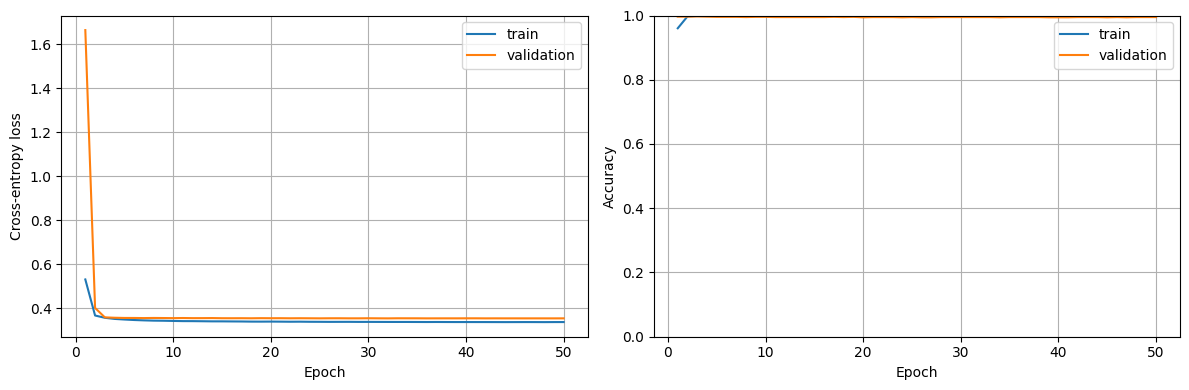

In [12]:
figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(12, 4))
loss_axis.plot(history['epoch'], history['train_loss'], label='train')
loss_axis.plot(history['epoch'], history['validation_loss'], label='validation')
loss_axis.set(xlabel='Epoch', ylabel='Cross-entropy loss')
loss_axis.grid(True); loss_axis.legend()
accuracy_axis.plot(history['epoch'], history['train_accuracy'], label='train')
accuracy_axis.plot(history['epoch'], history['validation_accuracy'], label='validation')
accuracy_axis.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1))
accuracy_axis.grid(True); accuracy_axis.legend()
figure.tight_layout(); plt.show()

## 6. Predict the test set and create `submission.csv`

Kaggle expects exactly 11,681 rows with the string columns `ID,Label`. Prediction IDs are carried through the data loader and merged into the public template, so batching cannot silently reorder the submission.

In [13]:
@torch.inference_mode()
def predict(model, loader):
    model.eval()
    predicted_ids = []
    predicted_indices = []
    for features, image_ids in loader:
        features = features.to(device=device, non_blocking=True)
        predicted_indices.extend(model(features).argmax(dim=1).cpu().tolist())
        predicted_ids.extend(image_ids.tolist())
    return predicted_ids, predicted_indices

predicted_ids, predicted_indices = predict(head, head_test_loader)
prediction_frame = pd.DataFrame({
    'ID': predicted_ids,
    'Label': [class_names[index] for index in predicted_indices],
})
if prediction_frame['ID'].duplicated().any():
    raise RuntimeError('Predictions contain duplicate IDs.')
if set(prediction_frame['Label']) - set(EXPECTED_CLASS_NAMES):
    raise RuntimeError('Predictions contain an invalid class label.')

submission = submission_template[['ID']].merge(
    prediction_frame, on='ID', how='left', validate='one_to_one'
)
if submission.columns.tolist() != ['ID', 'Label']:
    raise RuntimeError('Submission must contain exactly ID,Label.')
if len(submission) != EXPECTED_TEST_IMAGES or submission['Label'].isna().any():
    raise RuntimeError('Submission rows do not match the test set.')
if submission['ID'].tolist() != list(range(EXPECTED_TEST_IMAGES)):
    raise RuntimeError('Submission IDs are not ordered from 0 to 11680.')

SUBMISSION_PATH = ROOT / 'submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False)
print('Submission:', SUBMISSION_PATH)
print('Rows:', len(submission))
display(submission.head())
display(submission['Label'].value_counts().sort_index())

Submission: /content/submission.csv
Rows: 11681


,ID,Label
0,0,lions
1,1,lipsticks
2,2,cows
3,3,spiders
4,4,dogs


,count
Label,
birds,131
bottles,339
breads,310
butterflies,899
cakes,288
cats,928
chickens,847
cows,1036
dogs,780


## 7. Submit and improve

Download `submission.csv`, open your cohort's Kaggle competition, choose **Submit Predictions**, and upload the CSV. Do not upload the unchanged `my_solution.csv` placeholder.

Useful next experiments include stronger but still mild augmentation, deeper model architectures, regularization, learning-rate schedules, class-balanced sampling, and permitted pretrained models. Keep the validation split fixed while comparing experiments, and preserve the exact test IDs and canonical string labels.

In [14]:
# Run this cell in Google Colab to download the completed submission.
try:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))
except ImportError:
    print(f'Not running in Colab. Submission is saved at {SUBMISSION_PATH}.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>